# 01 TT 初期化のスケール診断

このNotebookは、00の学習を始める前の初期状態を調べる。学習そのものと、学習率の組み合わせ探索はしない。

比較するのは、同じ新規 `MNISTMLP` から作った3段階である。

- A: `fc1` がまだ dense なモデル。TT-SVD の前。
- B: `fc1` を TT-SVD し、rank 上限を掛けた直後。正準化はまだしない。既存の `factorize_named_tt_linear` では、TT-SVD と rank 上限はこの1回の処理である。
- C: B を site 0 中心に正準化したモデル。00が学習を始める状態はこちらである。

見たいのは、実効重みのノルムや表現がどの段階で変わり、その変化が初期の出力・活性化・勾配にどう出るかである。ノルムの比だけで、初期化の失敗や学習の停滞を断定しない。

今回分かることの限界は、末尾に分けて書く。02の学習ループは作らない。


## 1. 設定

00と同じ構成を使う。`fc1` は 784→512、`fc2` は 512→256、`fc3` は 256→10、活性化は ReLU だけである。

$$
\mathrm{OUT\_MODES}=(4,2,2,2,4,4),\qquad
\mathrm{IN\_MODES}=(2,2,2,2,7,7),\qquad
\mathrm{RANK\_CAP}=12.
$$

学習率も00の初期値のまま、両方 $10^{-3}$ とする。ここでは更新に使わず、相対更新量の尺度にだけ使う。

相対更新量は、既存実装と同じく次である。

$$
\frac{\eta \lVert g \rVert}{\lVert \theta \rVert}.
$$

$\theta$ が結合テンソル $T$ のときと、TT core 以外の通常 parameter を連結したベクトルのときとで、別々に計算する。分母が 0 で分子も 0 なら 0、分母だけが 0 なら値を作らずエラーにする。

乱数は `set_seed(0)` のあとでモデルを作る。データ分割は別の Generator を使うので、初期化の乱数とは混ぜない。


In [9]:
import csv
import json
import math
import os
import platform
import sys
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import tt_linear_initialization_stages
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate, measure_tt_pair_update_scales
from nn_compression.tt_mps import tt_matrix_ranks, tt_matrix_to_dense
from nn_compression.utils import find_project_root, get_experiment_dirs, set_seed


In [10]:
SEED = 0
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
RANK_CAP = 12
LAYER_NAME = "fc1"
PAIR_INDEX = 0
BATCH_SIZE = 64
DIAGNOSTIC_BATCH_SIZE = 64
TT_PAIR_LEARNING_RATE = 1e-3
DENSE_PARAMETER_LEARNING_RATE = 1e-3
SPLIT_LENGTHS = (50_000, 5_000, 5_000)

# B と C の実効重み・logits が、rank 制限そのものの差ではなく正準化の丸めに収まるかの目安。
# 00以前の float32 正準化では重みの最大差は 1e-6 前後だった。1e-4 と 1e-3 はその上の余裕であり、
# A と B の rank 制限差（ノルムが目に見えて変わる大きさ）を合格扱いにはしない。
CANONICAL_WEIGHT_MAX_ABS = 1e-4
CANONICAL_LOGITS_MAX_ABS = 1e-3

assert math.prod(OUT_MODES) == 512
assert math.prod(IN_MODES) == 784

set_seed(SEED)
project_root = find_project_root(Path.cwd())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "40_dmrg",
    "10_fashion_mnist_mlp",
    "01_tt_initialization_scale_diagnostics",
)
print("device:", DEVICE)
print("results:", results_dir)


device: cuda
results: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\01_tt_initialization_scale_diagnostics


## 2. 同じ初期値から A、B、C を作る

A は dense の複製、B は A の `fc1` だけを TT 化した複製、C は B をさらに正準化した複製である。B の core は C を作るときに上書きしない。`fc1.bias` と `fc2`、`fc3` は A からコピーした同じ値にする。

診断中に parameter は更新しない。比較の forward は `eval` にする。`MNISTMLP` には Dropout も BatchNorm もなく、ReLU は train と eval で同じである。そのことをモジュールの型で確認する。

出力と活性化は、学習分割の先頭 64 件で見る。この 64 件は index を直接読む。test と rank-selection validation は読まない。勾配の全データ集計とは別である。


In [11]:
fashion_root = data_dir / "FashionMNIST" / "raw"
required = [
    "train-images-idx3-ubyte",
    "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte",
    "t10k-labels-idx1-ubyte",
]
missing = [name for name in required if not (fashion_root / name).is_file()]
if missing:
    raise FileNotFoundError(
        "Fashion-MNIST がありません。代替データでは診断しない: " + ", ".join(missing)
    )

full_train, test_dataset = get_fashion_mnist_datasets(data_dir, download=False)
train_dataset, early_stopping_dataset, rank_validation_dataset = split_fashion_mnist_dataset(
    full_train,
    SPLIT_LENGTHS,
    seed=SEED,
)
assert len(train_dataset) == 50_000
gradient_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False
)
diagnostic_images = torch.stack(
    [train_dataset[index][0] for index in range(DIAGNOSTIC_BATCH_SIZE)]
).to(DEVICE)
diagnostic_labels = torch.tensor(
    [int(train_dataset[index][1]) for index in range(DIAGNOSTIC_BATCH_SIZE)],
    device=DEVICE,
)
print("diagnostic batch:", tuple(diagnostic_images.shape))
print("test is not scanned:", len(test_dataset))
print("rank-selection validation is not scanned:", len(rank_validation_dataset))

# データ分割のあとに新規 MLP を作る。分割は独自 Generator なので、この初期化乱数は消費しない。
dense_model = MNISTMLP().to(DEVICE)
stage_a, stage_b, stage_c = tt_linear_initialization_stages(
    dense_model,
    LAYER_NAME,
    OUT_MODES,
    IN_MODES,
    max_rank=RANK_CAP,
    canonical_center=0,
)
for stage in (stage_a, stage_b, stage_c):
    stage.to(DEVICE)
    stage.eval()

module_types = sorted({type(module).__name__ for module in stage_a.modules()})
print("module types:", module_types)
if any(name.startswith("Dropout") or name.startswith("BatchNorm") for name in module_types):
    raise RuntimeError(f"Dropout または BatchNorm があるため、比較条件を見直す: {module_types}")
print("forward mode: eval")
print("actual ranks B:", tt_matrix_ranks(list(stage_b.fc1.cores)))
print("actual ranks C:", tt_matrix_ranks(list(stage_c.fc1.cores)))


diagnostic batch: (64, 1, 28, 28)
test is not scanned: 10000
rank-selection validation is not scanned: 5000
module types: ['Linear', 'MNISTMLP', 'ReLU']
forward mode: eval
actual ranks B: (1, 8, 12, 12, 12, 12, 1)
actual ranks C: (1, 8, 12, 12, 12, 12, 1)


## 3. 実効重み

比較する行列は、`fc1` が表す dense 重み $W\in\mathbb{R}^{512\times 784}$ である。A は `fc1.weight`、B と C は TT core を `tt_matrix_to_dense` で戻した行列である。TT の forward 自体は、この dense 行列を作らない。ここでの復元は診断専用である。

基準は常に A とする。

$$
E_{\mathrm{rel}}(W)
=
\frac{\lVert W-W_A\rVert_F}{\lVert W_A\rVert_F},
\qquad
r(W)
=
\frac{\lVert W\rVert_F}{\lVert W_A\rVert_F},
\qquad
r_2(W)
=
\frac{\lVert W\rVert_F^2}{\lVert W_A\rVert_F^2}.
$$

$\lVert W_A\rVert_F=0$、または分母が有限でないときは、比を計算せず `undefined` と記録する。小さいという理由で分母を置き換えない。

B と C の差は $\lVert W_B-W_C\rVert_F$ と要素の最大絶対値である。正準化で core の数値そのものが変わることは、実効重みが保たれていれば異常にしない。


In [12]:
def frobenius(matrix):
    return float(torch.linalg.vector_norm(matrix.detach()))


def ratio_or_undefined(numerator, denominator):
    if not math.isfinite(numerator) or not math.isfinite(denominator) or denominator == 0.0:
        return None
    return numerator / denominator


weight_a = stage_a.fc1.weight.detach()
weight_b = tt_matrix_to_dense(list(stage_b.fc1.cores), OUT_MODES, IN_MODES).detach()
weight_c = tt_matrix_to_dense(list(stage_c.fc1.cores), OUT_MODES, IN_MODES).detach()
norm_a = frobenius(weight_a)
norm_b = frobenius(weight_b)
norm_c = frobenius(weight_c)
weights = {"A": weight_a, "B": weight_b, "C": weight_c}
norms = {"A": norm_a, "B": norm_b, "C": norm_c}

weight_rows = []
for name, matrix in weights.items():
    difference = frobenius(matrix - weight_a)
    weight_rows.append(
        {
            "stage": name,
            "shape": str(tuple(matrix.shape)),
            "dtype": str(matrix.dtype),
            "device": str(matrix.device),
            "frobenius_norm": norms[name],
            "relative_error_against_A": ratio_or_undefined(difference, norm_a),
            "norm_ratio_against_A": ratio_or_undefined(norms[name], norm_a),
            "squared_norm_ratio_against_A": ratio_or_undefined(norms[name] ** 2, norm_a ** 2),
            "all_finite": bool(torch.isfinite(matrix).all()),
        }
    )
bc_difference = frobenius(weight_b - weight_c)
bc_max_abs = float((weight_b - weight_c).abs().max())
print("||W_B - W_C||_F:", bc_difference)
print("max abs W_B - W_C:", bc_max_abs)
for row in weight_rows:
    print(row)


||W_B - W_C||_F: 7.270721198437968e-07
max abs W_B - W_C: 1.30385160446167e-08
{'stage': 'A', 'shape': '(512, 784)', 'dtype': 'torch.float32', 'device': 'cuda:0', 'frobenius_norm': 13.06302261352539, 'relative_error_against_A': 0.0, 'norm_ratio_against_A': 1.0, 'squared_norm_ratio_against_A': 1.0, 'all_finite': True}
{'stage': 'B', 'shape': '(512, 784)', 'dtype': 'torch.float32', 'device': 'cuda:0', 'frobenius_norm': 1.8824928998947144, 'relative_error_against_A': 0.9895621647398531, 'norm_ratio_against_A': 0.14410852339378102, 'squared_norm_ratio_against_A': 0.020767266514735934, 'all_finite': True}
{'stage': 'C', 'shape': '(512, 784)', 'dtype': 'torch.float32', 'device': 'cuda:0', 'frobenius_norm': 1.8824927806854248, 'relative_error_against_A': 0.9895621647398531, 'norm_ratio_against_A': 0.1441085142680761, 'squared_norm_ratio_against_A': 0.0207672638845523, 'all_finite': True}


## 4. 出力と活性化

固定した 64 件について、`MNISTMLP.forward` と同じ順で中間値を読む。`fc1` の線形出力、その ReLU 後、`fc2` の線形出力、その ReLU 後、logits である。

平均、標準偏差、RMS は、その tensor の全要素（batch と特徴をまとめたもの）に対する値である。標準偏差は母標準偏差（`unbiased=False`）とする。RMS は $\sqrt{\mathrm{mean}(x^2)}$ である。ゼロ率は、その tensor の要素のうち値がちょうど 0 である割合で、ReLU 後にだけ意味を持たせる。

logits 全体の標準偏差は、クラスごとの識別が強いかどうかの判定には使わない。loss はこの 64 件の平均 cross-entropy であり、全学習データの loss ではない。

B と C の logits と loss は、正準化の丸めの範囲で一致するかを見る。A と B は rank 上限で違ってよいので、一致は要求しない。


In [13]:
def scale_stats(tensor):
    values = tensor.detach().reshape(-1).to(dtype=torch.float64)
    return {
        "mean": float(values.mean()),
        "std": float(values.std(unbiased=False)),
        "rms": float(values.square().mean().sqrt()),
        "all_finite": bool(torch.isfinite(tensor).all()),
    }


def zero_rate(tensor):
    values = tensor.detach().reshape(-1)
    return float((values == 0).sum().to(dtype=torch.float64) / values.numel())


def read_forward(model, images):
    # MNISTMLP.forward と同じ順。中間値を読むためだけに、層を個別に呼ぶ。
    flat = images.view(images.shape[0], -1)
    fc1_out = model.fc1(flat)
    relu1 = model.relu1(fc1_out)
    fc2_out = model.fc2(relu1)
    relu2 = model.relu2(fc2_out)
    logits = model.fc3(relu2)
    return {
        "fc1_linear": fc1_out,
        "fc1_relu": relu1,
        "fc2_linear": fc2_out,
        "fc2_relu": relu2,
        "logits": logits,
    }


activation_rows = []
forward_by_stage = {}
with torch.no_grad():
    for name, model in (("A", stage_a), ("B", stage_b), ("C", stage_c)):
        parts = read_forward(model, diagnostic_images)
        forward_by_stage[name] = parts
        loss = F.cross_entropy(parts["logits"], diagnostic_labels)
        for part_name, tensor in parts.items():
            stats = scale_stats(tensor)
            activation_rows.append(
                {
                    "stage": name,
                    "tensor": part_name,
                    "scope": "diagnostic_batch_64_all_elements",
                    **stats,
                    "zero_rate": zero_rate(tensor) if part_name.endswith("relu") else None,
                    "diagnostic_batch_loss": float(loss) if part_name == "logits" else None,
                }
            )

logits_bc_max_abs = float((forward_by_stage["B"]["logits"] - forward_by_stage["C"]["logits"]).abs().max())
loss_b = next(
    row["diagnostic_batch_loss"]
    for row in activation_rows
    if row["stage"] == "B" and row["tensor"] == "logits"
)
loss_c = next(
    row["diagnostic_batch_loss"]
    for row in activation_rows
    if row["stage"] == "C" and row["tensor"] == "logits"
)
print("diagnostic-batch logits max abs B-C:", logits_bc_max_abs)
print("diagnostic-batch loss B, C:", loss_b, loss_c)
for row in activation_rows:
    if row["tensor"] in {"fc1_linear", "fc1_relu", "logits"}:
        print(row)


diagnostic-batch logits max abs B-C: 1.4901161193847656e-08
diagnostic-batch loss B, C: 2.296782970428467 2.296782970428467
{'stage': 'A', 'tensor': 'fc1_linear', 'scope': 'diagnostic_batch_64_all_elements', 'mean': 0.012078966295042903, 'std': 0.2685563251807256, 'rms': 0.2688278282122824, 'all_finite': True, 'zero_rate': None, 'diagnostic_batch_loss': None}
{'stage': 'A', 'tensor': 'fc1_relu', 'scope': 'diagnostic_batch_64_all_elements', 'mean': 0.10972982664164732, 'std': 0.16006465260315716, 'rms': 0.19406526703090216, 'all_finite': True, 'zero_rate': 0.47149658203125, 'diagnostic_batch_loss': None}
{'stage': 'A', 'tensor': 'logits', 'scope': 'diagnostic_batch_64_all_elements', 'mean': -0.005295926149119623, 'std': 0.0740276035834787, 'rms': 0.07421679679216557, 'all_finite': True, 'zero_rate': None, 'diagnostic_batch_loss': 2.2943081855773926}
{'stage': 'B', 'tensor': 'fc1_linear', 'scope': 'diagnostic_batch_64_all_elements', 'mean': -0.00013069935700671387, 'std': 0.0440359636441

## 5. 初期勾配と更新尺度

ここから先は、C の pair $(0,1)$ について、学習分割 50,000 件の平均 cross-entropy の勾配を使う。上の 64 件の loss とは別の量である。集計は 00 と同じく、batch の平均損失 $L_b$ に $n_b/N$ を掛けて足す。parameter は更新しない。SVD も通さない。

通常 parameter のノルムは、勾配を計算した `fc1.bias`、`fc2`、`fc3` を連結した L2 norm である。$T$ の勾配と、dense な $W$ の勾配は変数が違うので、ノルムの大小を同じ尺度としては読まない。正準化の前後で局所勾配が一致することも要求しない。勾配が有限でも、学習に十分だとは判定しない。

最初の pair だけを見るので、後ろの pair の勾配はこの診断では分からない。


In [14]:
# 全学習データ上の loss。勾配集計とは別の forward で、更新はしない。
criterion = torch.nn.CrossEntropyLoss()
full_train_loss_c, full_train_acc_c = evaluate(
    stage_c, gradient_loader, criterion, DEVICE
)
scales = measure_tt_pair_update_scales(
    stage_c,
    gradient_loader,
    layer_name=LAYER_NAME,
    pair_index=PAIR_INDEX,
    tt_pair_learning_rate=TT_PAIR_LEARNING_RATE,
    dense_parameter_learning_rate=DENSE_PARAMETER_LEARNING_RATE,
    device=DEVICE,
    criterion=criterion,
)
print("full-train loss/acc of C, not the 64-item batch:", full_train_loss_c, full_train_acc_c)
print("gradient scope: full training split, pair", PAIR_INDEX)
for key, value in scales.items():
    print(key, value)


full-train loss/acc of C, not the 64-item batch: 2.3034697688293457 0.09358
gradient scope: full training split, pair 0
pair_index 0
num_samples 50000
tt_parameter_norm 1.8824927806854248
tt_gradient_norm 0.007720186375081539
tt_relative_update 4.101044346247417e-06
dense_parameter_norm 9.435225486755371
dense_gradient_norm 0.04319494217634201
dense_relative_update 4.578050862374894e-06
gradients_finite True


## 6. 結果の読み方

左の図は実効重みの Frobenius norm である。A から B で下がるなら、変化は rank 上限つき TT-SVD の段階にある。B と C が重なるなら、正準化はノルムを作り直していない。

右の図は、64 件での `fc1` 線形出力の RMS である。logits の標準偏差とは別で、クラスの分離を表す図ではない。


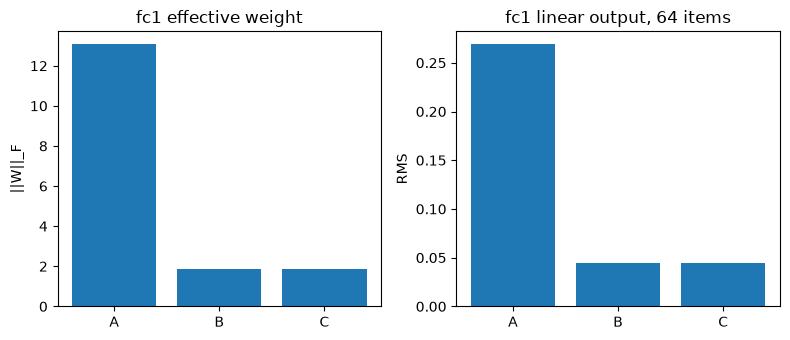

In [15]:
figure, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].bar(["A", "B", "C"], [norm_a, norm_b, norm_c])
axes[0].set_ylabel("||W||_F")
axes[0].set_title("fc1 effective weight")
fc1_rms = [
    next(row["rms"] for row in activation_rows if row["stage"] == name and row["tensor"] == "fc1_linear")
    for name in ("A", "B", "C")
]
axes[1].bar(["A", "B", "C"], fc1_rms)
axes[1].set_ylabel("RMS")
axes[1].set_title("fc1 linear output, 64 items")
figure.tight_layout()
figure.savefig(results_dir / "initialization_scale.png", dpi=120)
plt.show()


## 7. 判定と、02へ渡すもの

実装上の整合は、次が同時に成り立つかで見る。

- B と C の実効重みの最大絶対値が、上で決めた float32 の目安以下である。
- 同じ 64 件で、B と C の logits の最大絶対値が目安以下である。
- `fc1` の重み表現以外の state が A、B、C で完全一致する。
- 重み、出力、勾配が有限である。

この目安は、今回の float32 で正準化の丸めを見るためのもので、一般の最適基準ではない。A と B のノルム比が 1 から離れていても、それだけでは不合格にしない。

スケールの補正は、この診断だけでは入れない。rank 制限でノルムが変わることと、その後の学習が停滞することは、ここでは因果として確認できない。整合が取れた C は、02内の全比較条件で共有する新しいbaselineとして保存する。同じseed・設定でTT-SVDを再実行して作るため、00の保存checkpointと完全に同じstateとはみなさない。00の履歴と初期stateを厳密にそろえて比較する場合は、00の`initial_model.pt`を全条件へ直接読み込む。整合が崩れた場合は、採用済み初期状態としては保存しない。


In [16]:
def shared_state(model):
    kept = {}
    for name, tensor in model.state_dict().items():
        if name == "fc1.weight" or name.startswith("fc1.cores."):
            continue
        kept[name] = tensor.detach()
    return kept


shared = {name: shared_state(model) for name, model in (("A", stage_a), ("B", stage_b), ("C", stage_c))}
shared_name_sets = {name: set(state) for name, state in shared.items()}
shared_state_key_sets_equal = (
    shared_name_sets["A"] == shared_name_sets["B"] == shared_name_sets["C"]
)
shared_names = shared_name_sets["A"] if shared_state_key_sets_equal else set()
other_state_exact = shared_state_key_sets_equal and all(
    torch.equal(shared["A"][name], shared["B"][name]) and torch.equal(shared["B"][name], shared["C"][name])
    for name in shared_names
)
values_finite = (
    all(row["all_finite"] for row in weight_rows)
    and all(row["all_finite"] for row in activation_rows)
    and bool(scales["gradients_finite"])
    and math.isfinite(full_train_loss_c)
)
implementation_ok = (
    bc_max_abs <= CANONICAL_WEIGHT_MAX_ABS
    and logits_bc_max_abs <= CANONICAL_LOGITS_MAX_ABS
    and other_state_exact
    and values_finite
)

summary = {
    "implementation_ok": implementation_ok,
    "canonical_weight_max_abs_B_minus_C": bc_max_abs,
    "canonical_weight_frobenius_B_minus_C": bc_difference,
    "canonical_logits_max_abs_B_minus_C": logits_bc_max_abs,
    "shared_state_key_sets_equal": shared_state_key_sets_equal,
    "other_state_exact": other_state_exact,
    "values_finite": values_finite,
    "norm_A": norm_a,
    "norm_B": norm_b,
    "norm_C": norm_c,
    "norm_ratio_B_against_A": weight_rows[1]["norm_ratio_against_A"],
    "norm_ratio_C_against_A": weight_rows[2]["norm_ratio_against_A"],
    "full_train_loss_C": full_train_loss_c,
    "full_train_accuracy_C": full_train_acc_c,
    "gradient_scope": "full training split, pair 0 only",
    "activation_scope": "first 64 items of the training split",
    "scale_correction": "not applied",
    "unresolved": [
        "rank制限によるノルム変化が、その後の学習を停滞させるかは未確認",
        "pair 0 以外の初期勾配は未測定",
        "相対更新量が学習に十分かは、この診断だけでは判断しない",
        "同じseed・設定で再生成したstage Cは、00の保存checkpointとの完全一致を保証しない",
    ],
    "decision_for_02": (
        "stage C を02内の全条件で共有する新しいbaselineとして渡す。"
        "00の保存checkpointとの完全一致は仮定せず、スケール補正はしない。"
        if implementation_ok
        else "実装の整合が目安を外れたため、採用済み初期状態としては保存しない。"
    ),
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "device": str(DEVICE),
        "seed": SEED,
        "dtype": str(weight_a.dtype),
    },
}
print(json.dumps(summary, ensure_ascii=False, indent=2))

def write_csv(path, rows):
    fieldnames = list(rows[0])
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

write_csv(results_dir / "weight_comparison.csv", weight_rows)
write_csv(results_dir / "activation_scales.csv", activation_rows)
write_csv(
    results_dir / "gradient_scales.csv",
    [{key: value for key, value in scales.items()}],
)
(results_dir / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
(results_dir / "environment.json").write_text(
    json.dumps(summary["environment"], ensure_ascii=False, indent=2),
    encoding="utf-8",
)

if implementation_ok:
    torch.save(
        {
            "state_dict": stage_c.state_dict(),
            "layer_name": LAYER_NAME,
            "out_modes": list(OUT_MODES),
            "in_modes": list(IN_MODES),
            "rank_cap": RANK_CAP,
            "canonical_center": 0,
            "stage": "C",
            "seed": SEED,
            "baseline_scope": "shared baseline for 02; not asserted identical to 00 checkpoint",
        },
        models_dir / "initial_stage_c.pt",
    )
    print("saved initial stage C:", models_dir / "initial_stage_c.pt")
else:
    print("implementation check failed; adopted initial state was not saved")


{
  "implementation_ok": true,
  "canonical_weight_max_abs_B_minus_C": 1.30385160446167e-08,
  "canonical_weight_frobenius_B_minus_C": 7.270721198437968e-07,
  "canonical_logits_max_abs_B_minus_C": 1.4901161193847656e-08,
  "shared_state_key_sets_equal": true,
  "other_state_exact": true,
  "values_finite": true,
  "norm_A": 13.06302261352539,
  "norm_B": 1.8824928998947144,
  "norm_C": 1.8824927806854248,
  "norm_ratio_B_against_A": 0.14410852339378102,
  "norm_ratio_C_against_A": 0.1441085142680761,
  "full_train_loss_C": 2.3034697688293457,
  "full_train_accuracy_C": 0.09358,
  "gradient_scope": "full training split, pair 0 only",
  "activation_scope": "first 64 items of the training split",
  "scale_correction": "not applied",
  "unresolved": [
    "rank制限によるノルム変化が、その後の学習を停滞させるかは未確認",
    "pair 0 以外の初期勾配は未測定",
    "相対更新量が学習に十分かは、この診断だけでは判断しない",
    "同じseed・設定で再生成したstage Cは、00の保存checkpointとの完全一致を保証しない"
  ],
  "decision_for_02": "stage C を02内の全条件で共有する新しいbaselineとして渡す。00の保存checkpointと